# 06a. Case study: the summer 2012 central U.S. heat wave: observed event and simulation coverage

An ensemble, multi-start sensitivity case study of the late-June to early-July 2012 central U.S. heat episode, evaluated with event-centred and S2S lead-centred diagnostics under the prescribed observed SST of the F20TR hindcasts. It is one event seen from four overlapping May starts: the results are case-specific sensitivities to initialization, not climatological forecast skill. Process diagnostics (antecedent precipitation and soil moisture, surface energy partitioning, cloud and radiation, ridge evolution) follow in a later notebook once these results show what differs.

## Two evaluation frameworks

| Framework | Time coordinate | Question |
|---|---|---|
| Event-centred | calendar date | How well does each experiment represent the observed event window, seen from every start? |
| Lead-centred | lead day (lead 1 = the start date) | How does performance change over the standard S2S windows: week 1 (leads 1-7), week 2 (8-14), weeks 3-4 (15-28), weeks 5-6 (29-42) and weeks 7-8 (43-56, an extended-lead diagnostic)? |

The starts meet the same event at different leads (onset between lead 28 and 43, `coverage.csv`), so the lead windows complement the event window and do not replace it; the lead-window figure shades the windows that overlap the event for each start.

## Design: three questions

| Question | Experiments | Reading |
|---|---|---|
| Q1. Does event-informed initialization improve the event? | DA_COUPLED, DA_ATM and HYB_BASE against CLIM_BASE | benefit of the initialized states relative to CLIM_BASE, a free-climate-reference baseline whose atmospheric reference state is not initialized to the event, with DART-derived perturbations |
| Q2. Do the two initialization approaches differ? | DA_COUPLED against HYB_BASE | joint DART atmosphere-land initialization against the hybrid ERA5 atmosphere with DATM-forced land |
| Q3. What roles do the component states and their consistency play? | DA_ATM (DART atmosphere, reference land) and DA_LND (ERA5 atmosphere, DART land) with the two initialized configurations | component sensitivity; whether the joint result resembles one component experiment or differs from both. It does not by itself separate better component states from better atmosphere-land consistency. |

All are 20-member ensembles. Member numbers are labels: members are not paired across experiments, so experiments are compared as ensembles (`bootstrap_contrast` resamples the members of each ensemble independently). The 80 member-start combinations of an experiment are not 80 independent cases: they target the same event and neighbouring starts (5 days apart) overlap heavily. Start-resolved results are therefore primary; pooled results are descriptive only.

**Experiment QC (2026-11-06):** HYB_BASE and DA_LND started from an ERA5 atmosphere file without the radiative tracers (H2OLNZ, O3, N2OLNZ, CH4LNZ), aerosols and chemistry, and are about 6-7 K too cold over land from day 1 (`ic_defect`). They are left out of every score, ranking and contrast (`case.scored`) and appear only in the QC notebook (`06b`), where their errors reflect the missing tracers and say nothing about atmosphere-land consistency. Until their reruns from the completed initial files (steps 3a and 4a of `ensemble_perturbations/03_ic_era5_dartfill_dartpert.ipynb` and `04_ic_era5_climfill_dartpert.ipynb`) replace them, the provisional comparison is CLIM_BASE, DA_ATM and DA_COUPLED: Q1 only for DA_COUPLED and DA_ATM, and Q2 and the DA_LND part of Q3 cannot be answered. `IC_DEFECT = []` restores them everywhere.

## Event definition (from observations only)

Region `region` (default central U.S., 35-45N, 105-85W, land), daily-mean 2-m temperature (the archive has ERA5 daily means, not daily maxima, so this is a daily-mean heat event and does not verify station maximum-temperature records). A day is hot when the regional-mean ERA5 temperature exceeds its calendar-day `percentile` (90th) over `clim_years` without `exclude_years` (2012 is left out, so the event does not raise its own threshold) and +-`half_window` days; an event is at least `min_event_days` consecutive hot days. The event window is the observed event with the largest accumulated exceedance from June on, unless `event_window` is set. The gridpoint version of the same threshold gives the area above threshold. Notebook `06h` tests the threshold period (`sens_threshold_years`) and percentile (`sens_percentiles`).

## Reference states

| Quantity | Formula | Where |
|---|---|---|
| Absolute temperature error | $T_{model} - T_{obs}$ | `event_mean_T_error`; every score with `bias = "none"` |
| Observed-reference anomaly | $T_{model} - C_{obs}$ | `bias = "none"`: no mean-bias adjustment (the key is kept from notebooks 02-05; the observed climatology is still subtracted) |
| AMIP-reference anomaly | $T_{model} - C_{AMIP}$ | `bias = "amip"`: removes the background mean difference of the free-running AMIP runs from observations, not initialization- or lead-dependent hindcast drift |

Observations are always $T_{obs} - C_{obs}$ and the threshold always the observed one minus $C_{obs}$, so with `none` the model-minus-observed anomaly difference is the absolute error. Both climatologies are calendar-month means over the reference years (ERA5: monthly means of the ERA5 daily series; AMIP: monthly output of the two E3SMv3 AMIP runs), interpolated linearly between mid-month values (day 15) to each calendar day, as in notebooks 02-05 (`util/fcst_init_data.py`). The proper S2S reference, a hindcast climatology indexed by start season and lead and estimated from other years, cannot be built from four starts of one year; the AMIP adjustment is not equivalent to it.

## Metrics

*Event window, exact dates (primary):* event-mean absolute T error (K), event-mean anomaly (K), peak anomaly within the window (K) and its date error (days), exceedance days and longest run (days), accumulated exceedance (K day), mean area fraction above the gridpoint threshold (0-1), event-total precipitation (mm). *Timing-tolerant (secondary, window +-`peak_tolerance_days`):* peak anomaly and its date error, longest run. The peak is that of the anomaly series, searched by the same rules for observations and models.

*Ensemble, per start:* CRPS of the event-window mean and of the lead-window means (K); the event probability $p$, the member fraction with at least `min_event_days` consecutive hot days in the observed window (defined in advance), and its Brier score $(p - y)^2$, $y$ the observed outcome. With a single observed event the Brier score shows only how much probability went to what happened: it says nothing about reliability, discrimination or false alarms. No climatological skill reference is computed (a daily 90th percentile does not imply a 10 % probability of a 3-day event).

**The 06a-06h series** (summer 2012 central U.S. heat wave; each notebook reads the data it needs, computes, saves, then plots): `06a` observed event and simulation coverage; `06b` experiment QC; `06c` start-resolved regional trajectories; `06d` fixed-event-window metrics and maps; `06e` S2S lead-window scores; `06f` event probability; `06g` initialization contrasts; `06h` sensitivity of the event definition. Settings: `HeatwaveSettings` in `configs/hind_lead_eval_cases.py`; products: `util/heatwave_workflow.py`; methods: `util/heatwave_case.py`. Design, event definition and reference states: `06a`.

Every product is saved with the settings it was computed from and read back on the next run when those settings are unchanged; `FORCE_COMPUTE = True` recomputes this notebook's results, `FORCE_INPUTS = True` also re-reads the model output and observations. Model output is read only when a product has to be (re)computed.

## Outputs

`data/hind_lead_eval/heatwave_2012/`: `observed_fields.nc` (shared input of the series), `observed_events.csv`, `heat_metrics_obs.csv`, `coverage.csv`; figure `figure/hind_lead_eval/heatwave_2012/heatwave_coverage.png`.

## 1. Libraries

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display

## 2. User setup

Paths and run options; plain values only, so `papermill -p` overrides work. Case definitions (experiments, regions, windows, options) are the settings defaults; change them for this notebook with `CASE_OVERRIDES`.

In [2]:
INPUT_DATA_ROOT = Path("/global/cfs/cdirs/m4849/zhan391/eam_hindcast")
WORK_DIR = Path("/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026")
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")  # reference-data archive
LAND_SUPPORT_DIR = OBSERVATION_ROOT / "lnd_sea_mask"           # land fraction
AMIP_ROOT = OBSERVATION_ROOT / "E3SMv3"                        # free-running E3SMv3 DECK AMIP runs
WORKFLOW_NAME = "hind_lead_eval"

CONFIGS = {   # configuration key: raw case name (one case per start: INPUT_DATA_ROOT/<case name>_<YYYYMMDD>00/<ENxx>)
    "CLIM_BASE": "F20TR_ne30pg2_r05_IcoswISC30E3r5_CLIM_BASE",
    "HYB_BASE": "F20TR_ne30pg2_r05_IcoswISC30E3r5_HYB_BASE",
    "DA_COUPLED": "F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_COUPLED",
    "DA_ATM": "F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_ATM",
    "DA_LND": "F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_LND",
}
# the experiments analysed are the keys of CONFIGS, in this order (tables and legends)

CASE_OVERRIDES = {}     # changes to the HeatwaveSettings defaults (configs/hind_lead_eval_cases.py), e.g. {"event_window": ("2012-06-27", "2012-07-07")}
FORCE_COMPUTE = False    # recompute this notebook's results even when they are saved with the same settings
FORCE_INPUTS = False     # also re-read the model output and observations (slow)


## 3. Paths and modules

In [3]:
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
from configs.fcst_init_experiment_config import STYLE_MAP, set_case_names
from configs.hind_lead_eval_cases import HeatwaveSettings, RunPaths
from util.hind_case_io import figure_saver, write_dataset, write_table
from util.heatwave_workflow import HeatwaveCase

paths = RunPaths(*(Path(p) for p in (INPUT_DATA_ROOT, WORK_DIR, DIAGNOSTIC_OUTPUT_ROOT, OBSERVATION_ROOT,
                                     LAND_SUPPORT_DIR, AMIP_ROOT)), workflow_name=WORKFLOW_NAME)
set_case_names(CONFIGS)   # the readers find each configuration's cases by these names
for c, name in CONFIGS.items():
    print(f"[CASE] {c}: {name}_<YYYYMMDD>00")
case = HeatwaveCase(HeatwaveSettings(paths=paths, **{"configs": tuple(CONFIGS), **CASE_OVERRIDES}), force_compute=FORCE_COMPUTE,
                   force_inputs=FORCE_INPUTS)
cfg = case.cfg


[CASE] CLIM_BASE: F20TR_ne30pg2_r05_IcoswISC30E3r5_CLIM_BASE_<YYYYMMDD>00
[CASE] HYB_BASE: F20TR_ne30pg2_r05_IcoswISC30E3r5_HYB_BASE_<YYYYMMDD>00
[CASE] DA_COUPLED: F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_COUPLED_<YYYYMMDD>00
[CASE] DA_ATM: F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_ATM_<YYYYMMDD>00
[CASE] DA_LND: F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_LND_<YYYYMMDD>00
[DATA] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/heatwave_2012
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012
[SCORED] ['CLIM_BASE', 'DA_COUPLED', 'DA_ATM']
[QC ONLY] ['HYB_BASE', 'DA_LND']


## 4. Read input

ERA5 daily-mean TREFHT and GPCP precipitation on the map box, both climatologies and the calendar-day thresholds (`observed_fields.nc`), and from them the observed events and the event window.

In [4]:
obs = case.obs
print(f"[REGION] {cfg.region['name']}: {int(obs.mask.sum())} land points\n[CLIM] observed: {obs.clim_sources[0]}\n"
      f"[CLIM] model: {obs.clim_sources[1]}")

[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/heatwave_2012/observed_fields.nc
[EVENT] window 2012-06-27 to 2012-07-07, observed peak 2012-07-04
[REGION] CENTRAL_US: 200 land points
[CLIM] observed: ERA5 1x1 daily: monthly means of the daily series
[CLIM] model: E3SMv3 AMIP monthly (v3.LR.amip_0101, v3.LR.amip_0151; cmip_ts (time bounds))


## 5. Process and save

The observed events, the observed metrics on the event window, and the leads at which each start meets the window.

In [5]:
years = case.years
print(f"[YEARS] {cfg.clim_years[0]}-{cfg.clim_years[1]}"
      + (f" without {', '.join(map(str, cfg.exclude_years))}" if cfg.exclude_years else ""))
print("[CLIM] both: calendar-month means interpolated linearly between mid-month values to each day")
print(f"[CLIM] AMIP minus observed climatology over the region, window mean: "
      f"{float((obs.c_reg['amip'] - obs.c_reg['none']).sel(time=slice(*obs.window)).mean()):+.2f} K")
write_table(obs.events, case.data_dir / "observed_events.csv")
write_table(pd.DataFrame([obs.metrics]), case.data_dir / "heat_metrics_obs.csv")
write_table(obs.coverage, case.data_dir / "coverage.csv")
display(obs.events, pd.DataFrame([obs.metrics]).T.rename(columns={0: "observed"}), obs.coverage)

[YEARS] 2001-2014 without 2012
[CLIM] both: calendar-month means interpolated linearly between mid-month values to each day
[CLIM] AMIP minus observed climatology over the region, window mean: +1.33 K
[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/heatwave_2012/observed_events.csv
[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/heatwave_2012/heat_metrics_obs.csv
[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/heatwave_2012/coverage.csv


,onset,end,days,peak_date,peak_anomaly,mean_anomaly,accumulated_exceedance
0,2012-05-26,2012-05-28,3,2012-05-27,6.155478,5.064551,4.280816
1,2012-06-18,2012-06-20,3,2012-06-19,5.196135,4.439829,4.470446
2,2012-06-27,2012-07-07,11,2012-07-04,6.220895,5.324502,27.824396
3,2012-07-16,2012-07-19,4,2012-07-18,4.332666,4.147574,3.267218
4,2012-07-22,2012-07-25,4,2012-07-23,5.566126,5.118736,6.244453


,observed
event_mean_anomaly,5.324502
peak_anomaly,6.220895
peak_date_error_days,0.000000
exceedance_days,11.000000
longest_run_days,11.000000
accumulated_exceedance,27.824396
area_fraction_mean,0.783824
window_days_covered,11.000000
peak_anomaly_tol,6.220895
peak_date_error_tol_days,0.000000


,init,last_day,lead_at_onset,lead_at_end,window_covered
0,2012-05-16,2012-07-15,43,53,full
1,2012-05-21,2012-07-20,38,48,full
2,2012-05-26,2012-07-25,33,43,full
3,2012-05-31,2012-07-30,28,38,full


## 6. Plot and show

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_coverage.png


PosixPath('/global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_coverage.png')

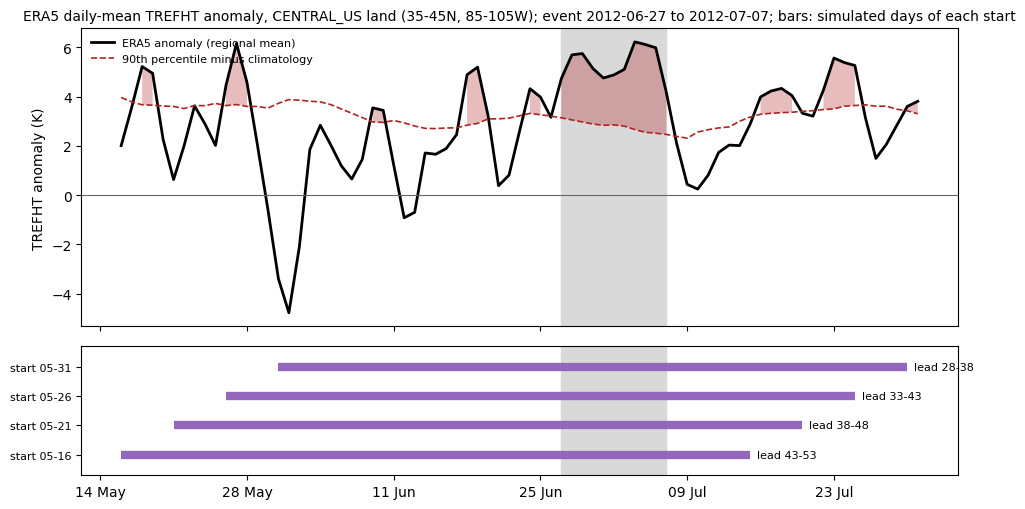

In [6]:
# ============================ Figure settings: edit here and rerun this cell ============================
SHOW = True          # False: save the figures without showing them
FIGURE_DPI = 200
FONT_SIZE = 18       # base font size (pt); every label of every figure scales with it
FONT_SCALES = dict(label=1.0, title=1.0, tick=0.9, legend=1.0, suptitle=1.15, cell=0.75)  # x FONT_SIZE

from util.fcst_init_plotting import set_font_size
set_font_size(FONT_SIZE, **FONT_SCALES)
save = figure_saver(case.figure_dir, dpi=FIGURE_DPI, show=SHOW)
# =========================================================================================================

from util.heatwave_case import plot_coverage

save(plot_coverage(obs.coverage, obs.window, obs.a, obs.thr_anom,
                   title=f"ERA5 daily-mean TREFHT anomaly, {case.label}; event {obs.window[0]} to {obs.window[1]}; "
                         f"bars: simulated days of each start"), "heatwave_coverage.png")